# 机器学习概述作业：完整参考答案

本文件保留原题、内置图片、给定数据生成器、随机种子、拟合求解器和全部自检；补全第1—5题推导、代码与分析，并保存实际运行的结果和两张图。

**姓名、学号：**原文件未提供，请自行填写。

回归模型只用训练集拟合、验证集选模；仅在最后一个评估单元格对所选模型计算一次测试 MSE，不根据测试结果重新选模或拟合。


## 运行准备

使用 Python 3.10 及以上，先运行下面的导入单元格。如缺少 NumPy 或 Matplotlib，可取消安装命令前的 `#` 后运行，按提示重启内核。全程不需要 GPU。


In [1]:
# 环境与辅助显示函数，已提供
# 如需安装，取消下一行注释。已有依赖时不必运行安装。
# %pip install numpy matplotlib

import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

def TODO(number):
    raise NotImplementedError(f"请先完成代码填空 {number}，再运行本单元格。")

def show_table(headers, rows):
    """已提供：把结果显示为 Notebook 内的 Markdown 表格。"""
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(str(x) for x in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


Python: 3.12.8
NumPy: 2.5.4
Matplotlib: 3.11.2


## 1. 正态分布均值的参数估计（20 分）

设 $x_1,\ldots,x_N$ 独立同分布于 $\mathcal N(\mu,\sigma^2)$，其中 $N\ge1$，$\mu$ 未知，$\sigma^2>0$ 已知。

**已知公式**：正态分布的概率密度为

$$p(z\mid m,v)=\frac{1}{\sqrt{2\pi v}}\exp\left[-\frac{(z-m)^2}{2v}\right],\qquad v>0,$$

其中 $m$ 为均值，$v$ 为方差。可直接使用该公式，无需背诵。求样本似然时代入相应的样本与参数；求先验密度时，把 $\mu$ 作为随机变量，均值为 $\mu_0$，方差为 $\sigma_0^2$。

1. 写出似然与对数似然，求导得到 $\mu$ 的最大似然估计。（10 分）
2. 设先验 $\mu\sim\mathcal N(\mu_0,\sigma_0^2)$，其中 $\mu_0$ 和 $\sigma_0^2>0$ 已知。写出对数后验中与 $\mu$ 有关的部分，并求 MAP 估计。（8 分）
3. 将 MAP 估计写成样本均值与先验均值的加权平均，说明固定两个方差时，$N$ 增大如何影响权重。（2 分）


### 第 1 题作答

**（1）最大似然估计 MLE**

由样本独立同分布，

$$L(\mu)=\prod_{i=1}^{N}\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\!\left[-\frac{(x_i-\mu)^2}{2\sigma^2}\right]
=(2\pi\sigma^2)^{-N/2}\exp\!\left[-\frac{1}{2\sigma^2}\sum_{i=1}^{N}(x_i-\mu)^2\right].$$

因此

$$\ell(\mu)=-\frac{N}{2}\log(2\pi\sigma^2)-\frac{1}{2\sigma^2}\sum_{i=1}^{N}(x_i-\mu)^2,$$

$$\frac{\mathrm d\ell}{\mathrm d\mu}
=\frac{1}{\sigma^2}\sum_{i=1}^{N}(x_i-\mu)=0
\quad\Longrightarrow\quad
\boxed{\hat\mu_{\mathrm{ML}}=\frac{1}{N}\sum_{i=1}^{N}x_i=\bar x}.$$

因为 $\ell''(\mu)=-N/\sigma^2<0$，该驻点是唯一的全局最大值。

**（2）最大后验估计 MAP**

先验密度为

$$p(\mu)=\frac{1}{\sqrt{2\pi\sigma_0^2}}
\exp\!\left[-\frac{(\mu-\mu_0)^2}{2\sigma_0^2}\right].$$

由后验正比于似然乘先验，保留与 $\mu$ 有关的项，

$$\log p(\mu\mid x_1,\ldots,x_N)
=C-\frac{1}{2\sigma^2}\sum_{i=1}^{N}(x_i-\mu)^2
-\frac{(\mu-\mu_0)^2}{2\sigma_0^2}.$$

$$\frac{\mathrm d}{\mathrm d\mu}\log p(\mu\mid x_1,\ldots,x_N)
=\frac{N(\bar x-\mu)}{\sigma^2}-\frac{\mu-\mu_0}{\sigma_0^2}=0.$$

整理得

$$\left(\frac{N}{\sigma^2}+\frac{1}{\sigma_0^2}\right)\mu
=\frac{N\bar x}{\sigma^2}+\frac{\mu_0}{\sigma_0^2},$$

$$\boxed{\hat\mu_{\mathrm{MAP}}
=\frac{N\bar x/\sigma^2+\mu_0/\sigma_0^2}{N/\sigma^2+1/\sigma_0^2}
=\frac{N\sigma_0^2\bar x+\sigma^2\mu_0}{N\sigma_0^2+\sigma^2}}.$$

对数后验的二阶导数为 $-N/\sigma^2-1/\sigma_0^2<0$，所以这也是唯一的全局最大值。

**（3）加权平均与样本量的影响**

$$\hat\mu_{\mathrm{MAP}}=a\bar x+(1-a)\mu_0,\qquad
\boxed{a=\frac{N\sigma_0^2}{N\sigma_0^2+\sigma^2}},\qquad
1-a=\frac{\sigma^2}{N\sigma_0^2+\sigma^2}.$$

两个方差固定时，$N$ 增大使 $a$ 增大：样本均值的权重增加，先验均值的权重减小；当 $N\to\infty$ 时，$a\to1$，MAP趋近于样本均值。小样本时，先验会把估计向 $\mu_0$ 收缩。


## 2. 高偏差与高方差分析（15 分）

固定一个测试输入 $x$，靶心代表最优预测值，蓝点代表同一学习算法在不同训练集上得到的预测。各训练集均从同一数据分布独立抽样。

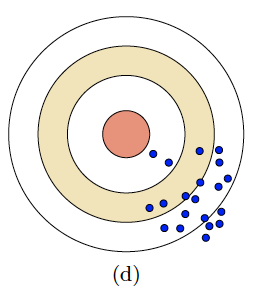

**给定情景**：某回归任务的真实输入输出关系明显非线性，但只使用原始输入的线性模型，未加入非线性特征。每次用于训练的样本很少，标签噪声也较大。重复抽样并训练后，模型在同一测试输入处的预测呈现上图所示的平均位置偏离靶心、预测较分散的现象。

1. 结合蓝点的平均位置和离散程度，解释高偏差和高方差。（4 分）
2. 根据给定情景，分别分析模型表达能力为何可能造成较高偏差，以及小样本和较大标签噪声为何可能使不同训练集得到的预测波动较大。不要求自行构造新情景。（8 分）
3. 针对上述原因提出两项改进，说明各自主要针对偏差还是方差。（3 分）


### 第 2 题分析

- **高偏差：**在固定输入 $x$ 处，蓝点的平均位置偏离靶心，说明对不同训练集取平均后的预测仍偏离最优预测 $f^*(x)$。偏差为 $\mathbb E_D[\hat f_D(x)]-f^*(x)$，高偏差表现为该系统性偏离较大。
- **高方差：**蓝点分散，说明换一批同分布训练样本，预测就可能明显改变，即 $\mathbb E_D[(\hat f_D(x)-\mathbb E_D\hat f_D(x))^2]$ 较大。它描述围绕平均预测的波动，与平均预测是否正确是两个不同问题。
- **表达能力的原因：**真实关系明显非线性，而模型只使用原始输入的线性函数，无法表示这种弯曲关系。即使估计参数很准确，也可能保留明显的模型误设误差，造成较高偏差。
- **小样本与噪声的原因：**样本少时，少量样本的选取和噪声就可能较大地改变斜率、截距等参数；标签噪声较大又增强这种不稳定性，所以重复训练得到的预测较分散。这不意味着所有线性模型都必然高方差，而是本题给定情景和观察所体现的现象。
- **改进一：加入合适的非线性特征。**例如在原输入之外加入低阶多项式特征，以提高表达能力，主要降低偏差；模型复杂度应通过验证集选择，因为过度扩展也可能增大方差。
- **改进二：增加同分布且有代表性的训练样本。**更多样本可减弱个别样本及其噪声对参数估计的影响，使重复训练更稳定，主要降低方差；这不能消除标签本身不可约的随机噪声。


## 3. 多分类评价指标手算（15 分）

每个样本恰有一个真实类别和一个预测类别。

| 样本 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|---|
| 真实标签 | 1 | 1 | 2 | 2 | 2 | 3 | 3 | 3 | 3 |
| 预测标签 | 1 | 2 | 2 | 2 | 3 | 3 | 3 | 1 | 2 |

对类别 $k$ 采用 one-vs-rest，其余类别视为负类。约定混淆矩阵**行为真实类别，列为预测类别**，顺序均为 1、2、3。

$$P_k=\frac{TP_k}{TP_k+FP_k},\quad R_k=\frac{TP_k}{TP_k+FN_k},\quad F1_k=\frac{2TP_k}{2TP_k+FP_k+FN_k}.$$

宏平均为逐类指标的算术平均，特别地 $F1_{\rm macro}=\frac13\sum_{k=1}^3F1_k$。微平均先将各类的 TP、FP、FN 分别相加，再代入对应公式。**分母为零时，该指标取零；宏平均仍含全部三个类别。**

1. 写出混淆矩阵及各类 TP、FP、FN。（4 分）
2. 手算各类 P、R、F1 及宏微平均，保留分数或 4 位小数，并给出计算过程。（6 分）
3. 计算 Accuracy，解释本题中微 P、微 R、微 F1 为什么都等于 Accuracy。（5 分）

请先完成手算，再用第4题的程序核验。


### 第 3 题作答

按“真实类别为行、预测类别为列”计数，

$$\boxed{C=\begin{bmatrix}1&1&0\\0&2&1\\1&1&2\end{bmatrix}}.$$

真实类别数量为 $(2,3,4)$，预测类别数量为 $(2,4,3)$。各类 $TP$ 为对角线；$FP$ 为对应列之和减 $TP$；$FN$ 为对应行之和减 $TP$。

| 类别 | TP | FP | FN | P | R | F1 |
|---|---:|---:|---:|---|---|---|
| 1 | 1 | 1 | 1 | $1/2=0.5000$ | $1/2=0.5000$ | $1/2=0.5000$ |
| 2 | 2 | 2 | 1 | $2/4=0.5000$ | $2/3=0.6667$ | $4/7=0.5714$ |
| 3 | 2 | 1 | 2 | $2/3=0.6667$ | $2/4=0.5000$ | $4/7=0.5714$ |

例如，第2类 $P_2=2/(2+2)=1/2$，$R_2=2/(2+1)=2/3$，$F1_2=4/(4+2+1)=4/7$；其余类别同理。

宏平均逐类计算后取平均：

$$P_{\mathrm{macro}}=\frac{1/2+1/2+2/3}{3}=\frac59,\qquad
R_{\mathrm{macro}}=\frac{1/2+2/3+1/2}{3}=\frac59,$$

$$F1_{\mathrm{macro}}=\frac{1/2+4/7+4/7}{3}=\frac{23}{42}.$$

注意：宏F1是三个类别F1的算术平均，不是把宏P、宏R再代入调和平均。

微平均先汇总：$\sum TP=5$、$\sum FP=4$、$\sum FN=4$，因此

$$P_{\mathrm{micro}}=\frac{5}{5+4}=\frac59,\quad
R_{\mathrm{micro}}=\frac{5}{5+4}=\frac59,\quad
F1_{\mathrm{micro}}=\frac{2\times5}{2\times5+4+4}=\frac59.$$

| 平均方式 | P | R | F1 |
|---|---|---|---|
| 宏平均 | $5/9=0.5556$ | $5/9=0.5556$ | $23/42=0.5476$ |
| 微平均 | $5/9=0.5556$ | $5/9=0.5556$ | $5/9=0.5556$ |

共9个样本，预测正确的是第1、3、4、6、7个，故

$$\boxed{\mathrm{Accuracy}=\frac59\approx0.5556}.$$

本题是单标签多分类，统计全部类别。每个正确样本贡献一个TP，每个错误样本同时为预测类贡献一个FP、为真实类贡献一个FN。若正确样本数为 $T$，则汇总后 $TP=T$、$FP=FN=N-T$，微P、微R和微F1便都等于 $T/N$，即Accuracy。


## 4. 指标实现与类别不平衡（20 分）

本题不需要训练分类器。只使用 Python／NumPy 实现指标，不调用现成分类指标函数。

1. 补全混淆矩阵和指标函数。（8 分）
2. 核验第3题手算；自造一个包含三个类别且完全预测正确的例子。（3 分）
3. 输出下列模型 A、B 的混淆矩阵、各类别 P／R／F1、宏微平均和 Accuracy。（4 分）
4. 根据整体正确率、各类同等重要这两种目标分别选模型，结合宏 F1 与各类召回率解释。（5 分）

下方已提供数据。`[1] * 16` 表示重复 16 次，`+` 表示拼接。


代码框架已经给出标签数组和零分母处理函数。先补全混淆矩阵、逐类指标和宏微平均，再运行下一单元格核验及比较。`axis=0` 按列汇总，`axis=1` 按行汇总；矩阵行为真实类别、列为预测类别。

**NumPy 用法提示**：`np.diag(A)` 取矩阵的主对角线；`A.sum(axis=0)` 得到各列之和，`A.sum(axis=1)` 得到各行之和；`a.mean()` 计算数组均值。已提供的 `safe_div(分子, 分母)` 按题目约定处理零分母。


In [2]:
# 第 4 题数据，已提供
y_true = np.array([1, 1, 2, 2, 2, 3, 3, 3, 3])
y_pred = np.array([1, 2, 2, 2, 3, 3, 3, 1, 2])
y_imbalanced = np.array([1] * 16 + [2] * 3 + [3])
pred_a = np.array([1] * 20)
pred_b = np.array([1] * 10 + [2] * 3 + [3] * 3 + [2] * 3 + [3])

# 已完成：完成混淆矩阵的行列下标
def confusion_matrix_3(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert y_true.ndim == 1 and y_true.shape == y_pred.shape and y_true.size > 0
    assert np.isin(y_true, [1, 2, 3]).all() and np.isin(y_pred, [1, 2, 3]).all()
    cm = np.zeros((3, 3), dtype=int)
    for truth, prediction in zip(y_true, y_pred):
        row = int(truth) - 1
        col = int(prediction) - 1
        cm[row, col] += 1
    return cm

# 已完成：完成指标计算，safe_div 已提供
def safe_div(num, den):
    num, den = np.broadcast_arrays(np.asarray(num, dtype=float), np.asarray(den, dtype=float))
    return np.divide(num, den, out=np.zeros_like(num), where=den != 0)

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix_3(y_true, y_pred)
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    precision = safe_div(tp, tp + fp)
    recall = safe_div(tp, tp + fn)
    f1 = safe_div(2 * tp, 2 * tp + fp + fn)
    macro = [precision.mean(), recall.mean(), f1.mean()]  # 顺序为 P、R、F1
    tp_total, fp_total, fn_total = tp.sum(), fp.sum(), fn.sum()
    micro_p = safe_div(tp_total, tp_total + fp_total)
    micro_r = safe_div(tp_total, tp_total + fn_total)
    micro_f1 = safe_div(2 * tp_total, 2 * tp_total + fp_total + fn_total)
    accuracy = safe_div(tp_total, cm.sum())
    return {"confusion": cm, "precision": precision, "recall": recall, "f1": f1,
            "macro": np.asarray(macro), "micro": np.array([micro_p, micro_r, micro_f1]),
            "accuracy": float(accuracy)}


In [3]:
# 自检：另一组小样本的矩阵与指标；不要删除
# 自检用另一组数据，检查矩阵方向与计数。
cm_check = confusion_matrix_3([1, 1, 2, 3], [1, 2, 2, 1])
np.testing.assert_array_equal(cm_check, [[1, 1, 0], [0, 1, 0], [1, 0, 0]])
print("4.1 自检通过")

# 独立小例子：检查逐类指标、宏 F1、微平均，以及从未预测出的类别。
check = compute_metrics([1, 1, 2, 3], [1, 2, 2, 1])
np.testing.assert_allclose(check["precision"], [1/2, 1/2, 0])
np.testing.assert_allclose(check["recall"], [1/2, 1, 0])
np.testing.assert_allclose(check["f1"], [1/2, 2/3, 0])
np.testing.assert_allclose(check["macro"], [1/3, 1/2, 7/18])
np.testing.assert_allclose(check["micro"], [1/2] * 3)
np.testing.assert_allclose(check["accuracy"], 1/2)
print("4.2 自检通过")

# 已完成：自造包含三个类别的完全正确例子；下方输出函数已提供
perfect_true = np.array([1, 2, 3, 1, 2, 3])
perfect_pred = np.array([1, 2, 3, 1, 2, 3])
assert perfect_true.size >= 3 and set(perfect_true.tolist()) == {1, 2, 3}
np.testing.assert_array_equal(perfect_true, perfect_pred)
perfect = compute_metrics(perfect_true, perfect_pred)
for name in ["precision", "recall", "f1", "macro", "micro"]:
    np.testing.assert_allclose(perfect[name], np.ones(3))
np.testing.assert_allclose(perfect["accuracy"], 1)
print("完全正确例子自检通过")

def report_metrics(name, result):
    display(Markdown(f"**{name}**"))
    show_table(["真实类别 / 预测类别", "1", "2", "3"],
               [[k+1, *result["confusion"][k]] for k in range(3)])
    rows = [[k+1, *[f"{result[m][k]:.4f}" for m in ["precision", "recall", "f1"]]]
            for k in range(3)]
    rows += [["宏平均", *[f"{v:.4f}" for v in result["macro"]]],
             ["微平均", *[f"{v:.4f}" for v in result["micro"]]]]
    show_table(["类别 / 平均方式", "P", "R", "F1"], rows)
    print(f"Accuracy = {result['accuracy']:.4f}")

original_metrics = compute_metrics(y_true, y_pred)
report_metrics("第3题数据", original_metrics)

# 输出模型 A、B 的结果，已提供
metrics_a = compute_metrics(y_imbalanced, pred_a)
metrics_b = compute_metrics(y_imbalanced, pred_b)
report_metrics("模型 A", metrics_a)
report_metrics("模型 B", metrics_b)


4.1 自检通过
4.2 自检通过
完全正确例子自检通过


**第3题数据**

| 真实类别 / 预测类别 | 1 | 2 | 3 |
| --- | --- | --- | --- |
| 1 | 1 | 1 | 0 |
| 2 | 0 | 2 | 1 |
| 3 | 1 | 1 | 2 |

| 类别 / 平均方式 | P | R | F1 |
| --- | --- | --- | --- |
| 1 | 0.5000 | 0.5000 | 0.5000 |
| 2 | 0.5000 | 0.6667 | 0.5714 |
| 3 | 0.6667 | 0.5000 | 0.5714 |
| 宏平均 | 0.5556 | 0.5556 | 0.5476 |
| 微平均 | 0.5556 | 0.5556 | 0.5556 |

Accuracy = 0.5556


...

Accuracy = 0.8000


**模型 B**

| 真实类别 / 预测类别 | 1 | 2 | 3 |
| --- | --- | --- | --- |
| 1 | 10 | 3 | 3 |
| 2 | 0 | 3 | 0 |
| 3 | 0 | 0 | 1 |

| 类别 / 平均方式 | P | R | F1 |
| --- | --- | --- | --- |
| 1 | 1.0000 | 0.6250 | 0.7692 |
| 2 | 0.5000 | 1.0000 | 0.6667 |
| 3 | 0.2500 | 1.0000 | 0.4000 |
| 宏平均 | 0.5833 | 0.8750 | 0.6120 |
| 微平均 | 0.7000 | 0.7000 | 0.7000 |

Accuracy = 0.7000


### 第 4 题分析

**手算与程序一致。**第3题的矩阵为 $[[1,1,0],[0,2,1],[1,1,2]]$，逐类P、R、F1以及宏微平均均与程序结果相符。所有给定自检以及包含三个类别的完全正确例子都通过；混淆矩阵保持真实类为行、预测类为列，宏平均始终包含全部三类。

**模型A的结果：**

$$C_A=\begin{bmatrix}16&0&0\\3&0&0\\1&0&0\end{bmatrix}.$$

| 类别 / 平均方式 | P | R | F1 |
|---|---:|---:|---:|
| 1 | 0.8000 | 1.0000 | 0.8889 |
| 2 | 0.0000 | 0.0000 | 0.0000 |
| 3 | 0.0000 | 0.0000 | 0.0000 |
| 宏平均 | 0.2667 | 0.3333 | 0.2963 |
| 微平均 | 0.8000 | 0.8000 | 0.8000 |

A的Accuracy为 $16/20=0.8000$，宏F1为 $(8/9+0+0)/3=8/27\approx0.2963$。类别2、3从未被预测，其精度分母为零，按题目约定取零，而不是从宏平均中删除。

**模型B的结果：**

$$C_B=\begin{bmatrix}10&3&3\\0&3&0\\0&0&1\end{bmatrix}.$$

| 类别 / 平均方式 | P | R | F1 |
|---|---:|---:|---:|
| 1 | 1.0000 | 0.6250 | 0.7692 |
| 2 | 0.5000 | 1.0000 | 0.6667 |
| 3 | 0.2500 | 1.0000 | 0.4000 |
| 宏平均 | 0.5833 | 0.8750 | 0.6120 |
| 微平均 | 0.7000 | 0.7000 | 0.7000 |

B的Accuracy为 $(10+3+1)/20=0.7000$，宏F1为 $(10/13+2/3+2/5)/3=358/585\approx0.6120$。

- **更关注整体正确率时选择A：**A正确16个，B正确14个，Accuracy分别为0.80与0.70。由于第1类有16个样本，占80%，全预测多数类也能获得较高Accuracy。
- **三个类别同等重要、兼顾查准率和查全率时选择B：**B的宏F1约0.6120，高于A的0.2963。A的两个少数类召回率都是0，B都是1，因此A的高整体正确率掩盖了对少数类的完全漏检。
- **B仍有不足：**它把6个第1类样本误报为少数类，使第2、3类精度只有0.50、0.25。选择B并不表示它所有指标都更好，而是它更符合本题“各类同等重要”的目标；这些结论只针对给定数据。


## 5. 回归模型复杂度与正则化（30 分）

使用给定数据生成器与求解器，比较欠拟合、过拟合和正则化的影响，不要求推导求解器。

$$x\sim U(-1,1),\qquad y=\sin(\pi x)+\varepsilon,\qquad\varepsilon\sim\mathcal N(0,0.2^2).$$

噪声与输入独立，样本之间独立。固定 `np.random.default_rng(42)`；依次生成训练集 30 个、验证集 60 个、测试集 200 个，每组先生成输入再生成噪声，不更改调用顺序。

$$f_d(x)=w_0+\sum_{j=1}^d w_jx^j,\qquad
J(w)=\frac1n\sum_{i=1}^n(y_i-f_d(x_i))^2+\lambda\sum_{j=1}^d w_j^2.$$

截距不正则化，特征不标准化。候选模型依次为 $(d,\lambda)=(1,0),(3,0),(9,0),(9,0.0001),(9,0.01),(9,1)$。

**模型说明**：多项式可以看作对输入做固定的特征变换。例如三次模型使用

$$\phi_3(x)=[1,x,x^2,x^3],\qquad f_3(x)=w_0+w_1x+w_2x^2+w_3x^3.$$

虽然模型对输入 $x$ 可以是非线性的，但对待学习参数 $w_0,\ldots,w_d$ 仍然是线性的，因此可以沿用线性回归的拟合方法。`features(x, degree)` 已经生成这些特征，每行对应一个样本。

**数据集用途**：

- 训练集用于拟合模型参数 $w$；每个候选模型都只在训练集上拟合。
- 验证集用于比较候选模型，选择次数 $d$ 和正则化系数 $\lambda$。
- 测试集用于模型选择结束后的最终评估。不能根据测试结果重新选择模型。本题保留所选模型已训练好的参数，不重新拟合。

**求解器使用范围**：直接调用已提供的 `fit_model` 即可；不要求推导或解释其中的增广矩阵、`np.vander` 或 `np.linalg.lstsq`。本题重点是预测、误差计算、模型比较与结果分析。

1. 比较无正则化的 1、3、9 次模型，报告训练／验证 MSE，并画拟合曲线、真实函数与训练点。（10 分）
2. 固定 9 次，比较四个正则化系数；报告训练／验证 MSE，绘制六个候选的误差对比图。**MSE 不含正则项。**（8 分）
3. 仅按验证 MSE 选一个模型；并列时选列表靠前者。保持已训练参数不变，只对最终模型计算一次测试 MSE。（4 分）
4. 完成结果分析。（8 分）

所有候选只使用训练集拟合。测试集仅在最后一个评估单元格使用，不参与模型和参数选择。


下面已给出数据生成、多项式特征和拟合求解器。请保留这些部分，补全预测、MSE、候选模型拟合和验证集选模的 TODO。绘图和结果表的框架可直接使用。


In [4]:
# 数据准备与拟合求解器，已提供；不改变随机种子和抽样顺序
def regression_data():
    """不要改变种子、调用顺序、样本数或噪声标准差。"""
    rng = np.random.default_rng(42)

    def draw(n):
        x = rng.uniform(-1.0, 1.0, n)
        y = np.sin(np.pi * x) + rng.normal(0.0, 0.2, n)
        return x, y

    train = draw(30)
    valid = draw(60)
    test = draw(200)
    return train, valid, test


def features(x, degree):
    return np.vander(np.asarray(x), N=degree + 1, increasing=True)


def fit_model(x, y, degree, lam=0.0):
    """已提供的求解器：最小化 mean((Phi @ w-y)**2)+lam*sum(w[1:]**2)。
    截距不受惩罚；使用最小二乘求解，避免显式矩阵求逆。
    学生可直接调用，不要求推导增广矩阵。
    """
    phi = features(x, degree)
    penalty = np.eye(degree + 1)
    penalty[0, 0] = 0.0
    a = np.vstack([phi, np.sqrt(len(x) * lam) * penalty])
    b = np.concatenate([y, np.zeros(degree + 1)])
    return np.linalg.lstsq(a, b, rcond=None)[0]


CANDIDATES = [(1, 0.0), (3, 0.0), (9, 0.0),
              (9, 1e-4), (9, 1e-2), (9, 1.0)]

(train_x, train_y), (valid_x, valid_y), (test_x, test_y) = regression_data()
print("样本数（训练 / 验证 / 测试）：", len(train_x), len(valid_x), len(test_x))


样本数（训练 / 验证 / 测试）： 30 60 200


In [5]:
# 已完成：完成预测与 MSE；features 返回多项式设计矩阵
def predict(x, degree, weights):
    return features(x, degree) @ weights

def mse(y_true, y_prediction):
    return float(np.mean((np.asarray(y_true) - np.asarray(y_prediction)) ** 2))

# 自检：预测与 MSE 的独立小例子
np.testing.assert_allclose(predict(np.array([0, 1, 2]), 1, np.array([1, 2])), [1, 3, 5])
np.testing.assert_allclose(mse(np.array([1, 2, 3]), np.array([1, 3, 2])), 2/3)
np.testing.assert_allclose(mse(np.array([1, 2]), np.array([1, 2])), 0)
print("5.1 自检通过")


5.1 自检通过


In [6]:
# 已完成：只使用训练集拟合，分别计算训练和验证 MSE
results = []
all_weights = []
for degree, lam in CANDIDATES:
    weights = fit_model(train_x, train_y, degree, lam)
    train_prediction = predict(train_x, degree, weights)
    valid_prediction = predict(valid_x, degree, weights)
    train_error = mse(train_y, train_prediction)
    valid_error = mse(valid_y, valid_prediction)
    results.append({"degree": degree, "lam": lam,
                    "train_mse": train_error, "valid_mse": valid_error})
    all_weights.append(weights)

show_table(["次数 d", "λ", "训练 MSE", "验证 MSE"],
           [[r["degree"], r["lam"], f"{r['train_mse']:.6f}", f"{r['valid_mse']:.6f}"]
            for r in results])

# 自检：结果结构与取值范围
assert len(results) == len(CANDIDATES) == len(all_weights) == 6
for row, weights, (degree, lam) in zip(results, all_weights, CANDIDATES):
    assert row["degree"] == degree and row["lam"] == lam
    assert weights.shape == (degree + 1,)
    assert np.isfinite([row["train_mse"], row["valid_mse"]]).all()
    assert row["train_mse"] >= 0 and row["valid_mse"] >= 0
print("结果结构与数值范围自检通过；是否使用正确数据仍需自行核对。")


| 次数 d | λ | 训练 MSE | 验证 MSE |
| --- | --- | --- | --- |
| 1 | 0.0 | 0.216077 | 0.260746 |
| 3 | 0.0 | 0.023660 | 0.047650 |
| 9 | 0.0 | 0.019445 | 0.051201 |
| 9 | 0.0001 | 0.020108 | 0.053206 |
| 9 | 0.01 | 0.045185 | 0.097193 |
| 9 | 1.0 | 0.383887 | 0.503866 |

结果结构与数值范围自检通过；是否使用正确数据仍需自行核对。


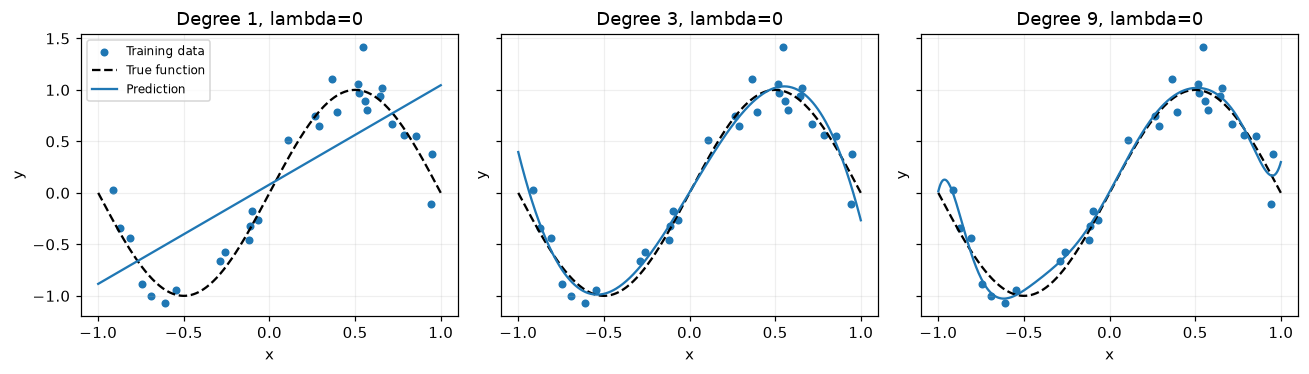

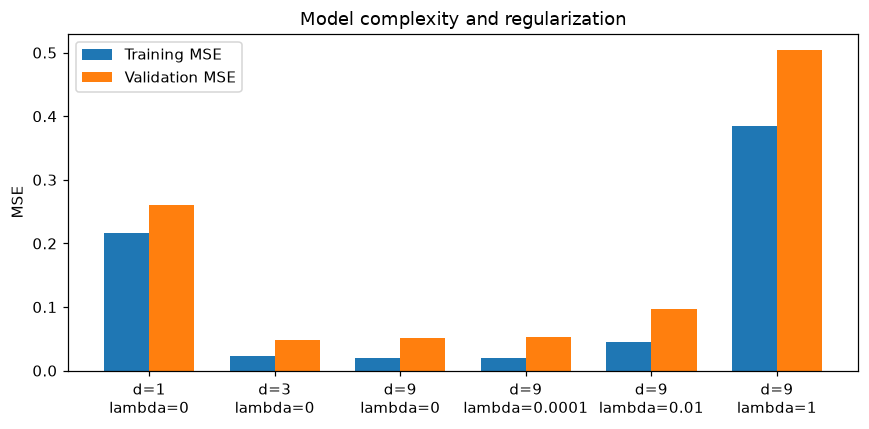

In [7]:
# 已完成：完成网格上的预测；其余绘图框架已提供
grid = np.linspace(-1, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, row, weights in zip(axes, results[:3], all_weights[:3]):
    grid_prediction = predict(grid, row["degree"], weights)
    ax.scatter(train_x, train_y, s=18, label="Training data")
    ax.plot(grid, np.sin(np.pi * grid), "k--", label="True function")
    ax.plot(grid, grid_prediction, label="Prediction")
    ax.set(title=f"Degree {row['degree']}, lambda=0", xlabel="x", ylabel="y")
    ax.grid(alpha=0.2)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(results))
ax.bar(positions - 0.18, [r["train_mse"] for r in results], 0.36, label="Training MSE")
ax.bar(positions + 0.18, [r["valid_mse"] for r in results], 0.36, label="Validation MSE")
ax.set_xticks(positions, [f"d={r['degree']}\nlambda={r['lam']:g}" for r in results])
ax.set(ylabel="MSE", title="Model complexity and regularization")
ax.legend()
fig.tight_layout()
plt.show()


In [8]:
# 已完成：仅按验证误差选模型，np.argmin 返回最小值第一次出现的下标
selection_errors = [row["valid_mse"] for row in results]
best_index = int(np.argmin(selection_errors))
best_model = results[best_index]
best_weights = all_weights[best_index]
print(f"所选模型：d={best_model['degree']}, λ={best_model['lam']:g}")
print(f"验证 MSE：{best_model['valid_mse']:.6f}")

# 仅在完成模型选择后使用测试集。
test_mse = mse(test_y, predict(test_x, best_model["degree"], best_weights))
print(f"最终模型测试 MSE：{test_mse:.6f}")


所选模型：d=3, λ=0
验证 MSE：0.047650
最终模型测试 MSE：0.048308


### 第 5 题分析

实际结果如下（MSE不含正则项）：

| 次数 d | λ | 训练 MSE | 验证 MSE |
|---|---:|---:|---:|
| 1 | 0 | 0.216077 | 0.260746 |
| 3 | 0 | 0.023660 | 0.047650 |
| 9 | 0 | 0.019445 | 0.051201 |
| 9 | 0.0001 | 0.020108 | 0.053206 |
| 9 | 0.01 | 0.045185 | 0.097193 |
| 9 | 1 | 0.383887 | 0.503866 |

**1. 欠拟合：**无正则化的一次模型表现出欠拟合。训练MSE为0.216077、验证MSE为0.260746，均明显高于三次模型的0.023660和0.047650。拟合曲线是一条直线，无法跟随真实正弦函数的弯曲走势，说明模型表达能力不足。

**2. 无正则化时的复杂度：**从1次升至3次，训练MSE从0.216077降至0.023660，验证MSE从0.260746降至0.047650，模型更好地表示了真实函数。继续升至9次，训练MSE进一步降至0.019445，但验证MSE反而升至0.051201；9次曲线在区间两端出现额外弯折，更复杂的曲线更贴近训练点，却没有得到更好的验证表现，出现轻度过拟合迹象。因此，提高次数并不总能改善泛化。

**3. 固定9次时的正则化：**本次随 $\lambda=0,10^{-4},10^{-2},1$ 增大，验证MSE依次为0.051201、0.053206、0.097193、0.503866，反而逐步增大。较大的正则化限制了非截距系数，可能在降低对样本波动的敏感性的同时引入过大偏差；$\lambda=1$时连训练MSE也升至0.383887，说明限制过强。这里使用未标准化的单项式特征，同一L2惩罚对不同幂次系数的函数效果也不相同。正则化是否有益需要验证，而不能预设“越强越好”。这一组单次抽样结果也不能直接测量理论偏差、方差，或证明正则化在其他数据上无效。

**4. 选模与最终评估：**只看训练误差会偏向表达能力更强的模型；本题9次无正则化的训练误差最低，但其验证误差高于3次模型。验证集用于比较6个候选，`np.argmin`按列表顺序处理并列；本次选择 $(d,\lambda)=(3,0)$，验证MSE为0.047650。保留它在30个训练样本上拟合得到的参数，不用训练集和验证集重新拟合，再在独立测试集上只计算一次MSE。测试集用于最终评估，不能用来反过来修改次数、正则化参数或模型选择。


本次最终所选模型的测试 MSE 为 **0.048308**（见上方唯一一次测试评估输出）；模型选择仍只使用验证MSE。


## 提交要求

提交填写完成的 Notebook，命名为 `学号_姓名_机器学习概述.ipynb`。请确保代码、图表和文字分析均已保留，无需另交 Word 或 PDF。

提交前请重启内核并从头运行全部单元格，检查：

- 姓名、学号和理论／分析题均已填写。
- 所有 `TODO("编号")` 均已替换，运行无报错。辅助函数 `def TODO(number)` 可以保留。
- 结果表、自检输出及两张回归图完整；未修改数据、随机种子或自检。
- 未使用测试集选择模型或参数。
